In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:

# Importing libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Loading dataset
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')

# Display first five rows
train.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:

print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

print("\nTraining Dataset Information:")
train.info()


Training Shape: (1460, 81)
Testing Shape: (1459, 80)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle  

In [4]:

# Statistical summary of numerical columns

train.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:

# Numerical columns
num_cols = train.select_dtypes(include=['int64', 'float64']).columns

# Categorical columns
cat_cols = train.select_dtypes(include=['object']).columns

print("Number of Numerical Features:", len(num_cols))
print("Number of Categorical Features:", len(cat_cols))

print("\nNumerical Features:")
print(num_cols.tolist())

print("\nCategorical Features:")
print(cat_cols.tolist())


Number of Numerical Features: 38
Number of Categorical Features: 43

Numerical Features:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'Heating

In [6]:

print("Target Variable Statistics:")
print(train['SalePrice'].describe())

print("\nSkewness:", train['SalePrice'].skew())


Target Variable Statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.8828757597682129


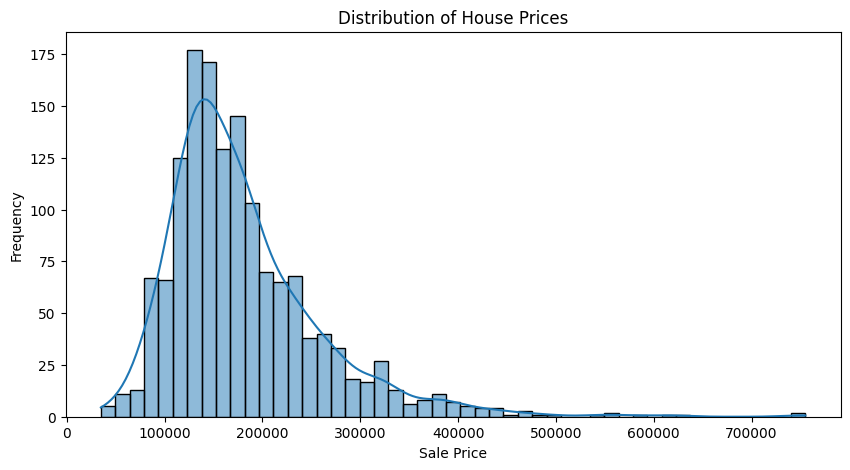

In [7]:

plt.figure(figsize=(10, 5))

sns.histplot(train['SalePrice'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()


In [8]:

missing_values = train.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

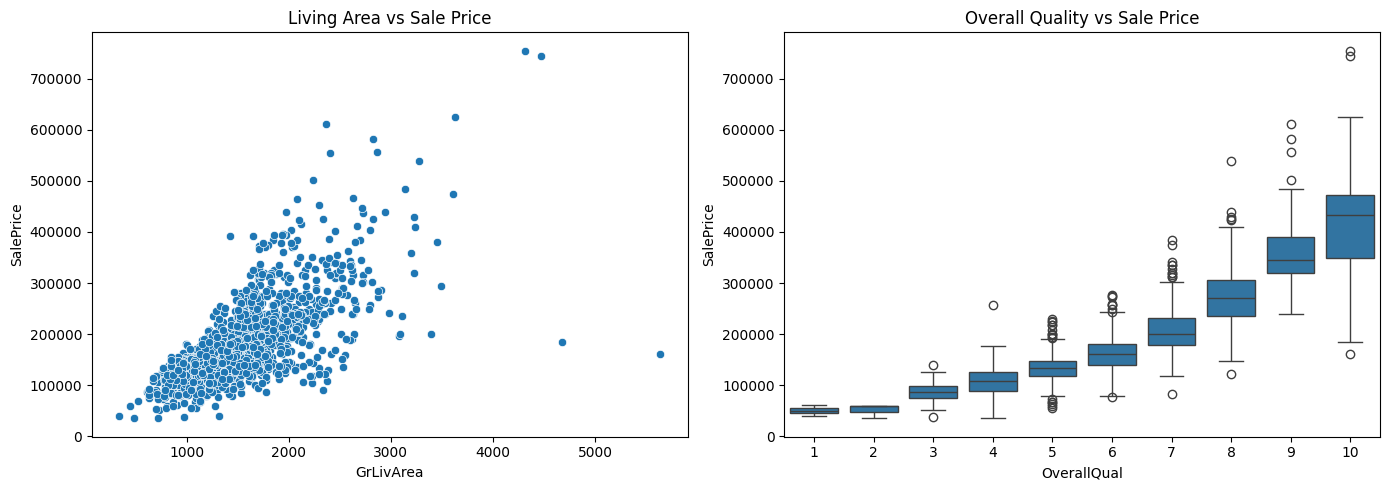

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=train, x='GrLivArea', y='SalePrice', ax=axes[0])
axes[0].set_title("Living Area vs Sale Price")

sns.boxplot(data=train, x='OverallQual', y='SalePrice', ax=axes[1])
axes[1].set_title("Overall Quality vs Sale Price")

plt.tight_layout()
plt.show()


In [10]:

# Separate input features and target variable

X = train.drop(['SalePrice', 'Id'], axis=1)
y = train['SalePrice']

# Remove ID from test dataset
X_test = test.drop(['Id'], axis=1)

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Test Shape:", X_test.shape)


X Shape: (1460, 79)
y Shape: (1460,)
Test Shape: (1459, 79)


In [11]:

# Identify numerical and categorical columns

num_features = X.select_dtypes(include=['int64', 'float64']).columns
cat_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:", len(num_features))
print("Categorical Features:", len(cat_features))


Numerical Features: 36
Categorical Features: 43


In [12]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)


Training Features: (1168, 79)
Validation Features: (292, 79)


In [14]:

# Fit preprocessing only on training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and competition test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Validation Shape:", X_val_processed.shape)
print("Processed Test Shape:", X_test_processed.shape)


Processed Training Shape: (1168, 285)
Processed Validation Shape: (292, 285)
Processed Test Shape: (1459, 285)


In [15]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

# Gradient Boosting parameters

n_estimators = 5
learning_rate = 0.1
max_depth = 2

print("Number of Trees:", n_estimators)
print("Learning Rate:", learning_rate)
print("Maximum Tree Depth:", max_depth)


Number of Trees: 5
Learning Rate: 0.1
Maximum Tree Depth: 2


In [16]:

# Initial prediction using mean of target values

initial_prediction = np.mean(y_train)

# Assign the same prediction to every training sample
y_pred = np.full(
    shape=len(y_train),
    fill_value=initial_prediction
)

print("Initial Prediction:", initial_prediction)

print("\nFirst 10 Predictions:")
print(y_pred[:10])


Initial Prediction: 181441.5419520548

First 10 Predictions:
[181441.54195205 181441.54195205 181441.54195205 181441.54195205
 181441.54195205 181441.54195205 181441.54195205 181441.54195205
 181441.54195205 181441.54195205]


In [17]:

# Calculate residuals

residuals = y_train.values - y_pred

# Display actual values, predictions and residuals
residual_df = pd.DataFrame({
    'Actual Price': y_train.values,
    'Initial Prediction': y_pred,
    'Residuals': residuals
})

residual_df.head(10)


,Actual Price,Initial Prediction,Residuals
0,145000,181441.541952,-36441.541952
1,178000,181441.541952,-3441.541952
2,85000,181441.541952,-96441.541952
3,175000,181441.541952,-6441.541952
4,127000,181441.541952,-54441.541952
5,149900,181441.541952,-31541.541952
6,174000,181441.541952,-7441.541952
7,125500,181441.541952,-55941.541952
8,175500,181441.541952,-5941.541952
9,225000,181441.541952,43558.458048


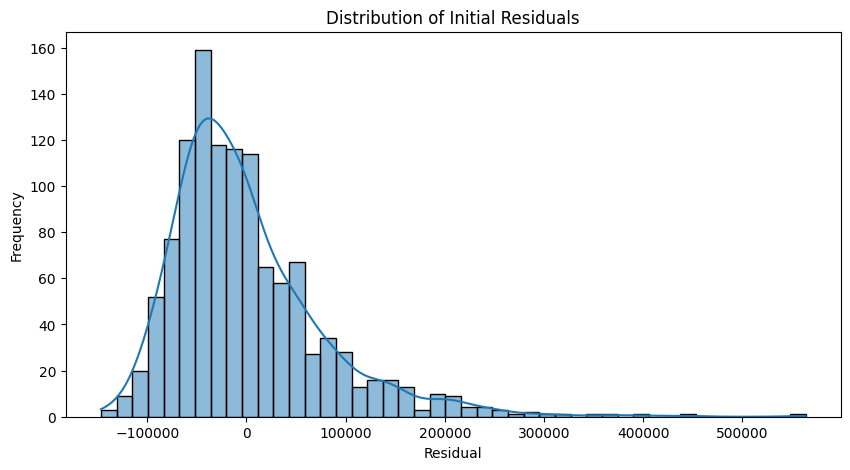

In [18]:

plt.figure(figsize=(10, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Initial Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.show()


In [19]:

# Create the first Decision Tree Regressor

tree = DecisionTreeRegressor(
    max_depth=max_depth,
    random_state=42
)

# Train the tree using residuals
tree.fit(X_train_processed, residuals)

print("First Decision Tree trained successfully!")


First Decision Tree trained successfully!


In [20]:

# Predict residuals using the first tree

tree_predictions = tree.predict(X_train_processed)

print("Actual Residuals:")
print(residuals[:10])

print("\nPredicted Residuals:")
print(tree_predictions[:10])


Actual Residuals:
[-36441.54195205  -3441.54195205 -96441.54195205  -6441.54195205
 -54441.54195205 -31541.54195205  -7441.54195205 -55941.54195205
  -5941.54195205  43558.45804795]

Predicted Residuals:
[-39363.89870137 -39363.89870137 -39363.89870137 -39363.89870137
 -39363.89870137 -39363.89870137 -39363.89870137 -39363.89870137
 -39363.89870137  93598.73212202]


In [21]:

residual_comparison = pd.DataFrame({
    'Actual Residual': residuals[:10],
    'Predicted Residual': tree_predictions[:10]
})

residual_comparison


,Actual Residual,Predicted Residual
0,-36441.541952,-39363.898701
1,-3441.541952,-39363.898701
2,-96441.541952,-39363.898701
3,-6441.541952,-39363.898701
4,-54441.541952,-39363.898701
5,-31541.541952,-39363.898701
6,-7441.541952,-39363.898701
7,-55941.541952,-39363.898701
8,-5941.541952,-39363.898701
9,43558.458048,93598.732122


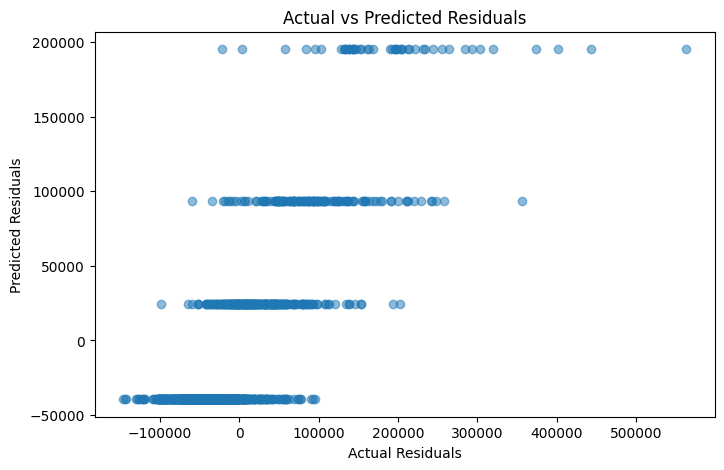

In [22]:

plt.figure(figsize=(8, 5))

plt.scatter(residuals, tree_predictions, alpha=0.5)

plt.xlabel("Actual Residuals")
plt.ylabel("Predicted Residuals")
plt.title("Actual vs Predicted Residuals")

plt.show()


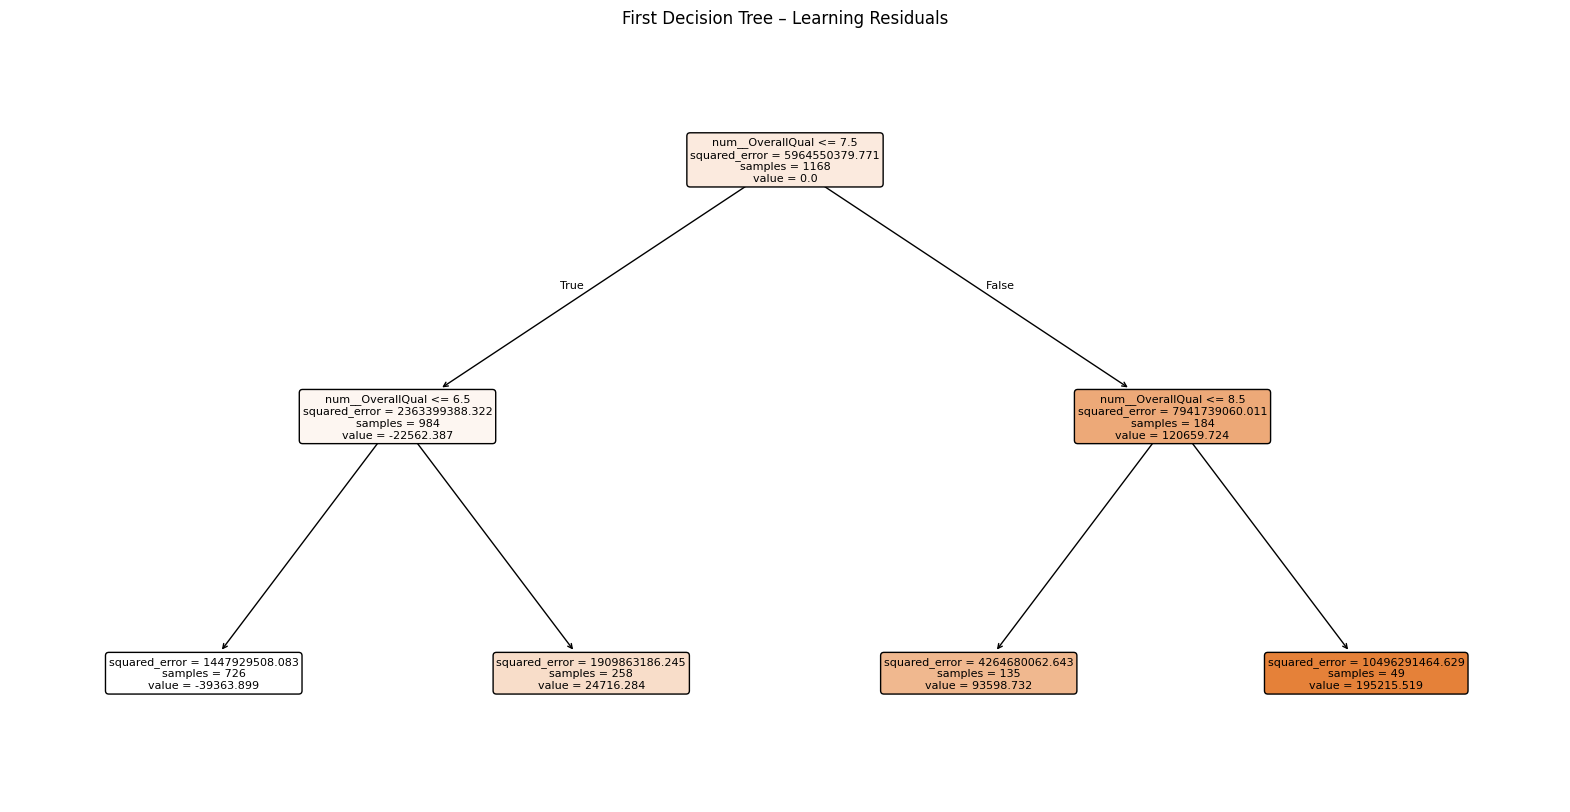

In [23]:

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    max_depth=2,
    filled=True,
    rounded=True,
    feature_names=preprocessor.get_feature_names_out(),
    fontsize=8
)

plt.title("First Decision Tree – Learning Residuals")
plt.show()


In [24]:

# Update predictions using learning rate

updated_predictions = y_pred + (learning_rate * tree_predictions)

print("Initial Predictions:")
print(y_pred[:10])

print("\nTree Predictions:")
print(tree_predictions[:10])

print("\nUpdated Predictions:")
print(updated_predictions[:10])


Initial Predictions:
[181441.54195205 181441.54195205 181441.54195205 181441.54195205
 181441.54195205 181441.54195205 181441.54195205 181441.54195205
 181441.54195205 181441.54195205]

Tree Predictions:
[-39363.89870137 -39363.89870137 -39363.89870137 -39363.89870137
 -39363.89870137 -39363.89870137 -39363.89870137 -39363.89870137
 -39363.89870137  93598.73212202]

Updated Predictions:
[177505.15208192 177505.15208192 177505.15208192 177505.15208192
 177505.15208192 177505.15208192 177505.15208192 177505.15208192
 177505.15208192 190801.41516426]


In [25]:

prediction_comparison = pd.DataFrame({
    'Actual Price': y_train.values[:10],
    'Initial Prediction': y_pred[:10],
    'Tree Prediction': tree_predictions[:10],
    'Updated Prediction': updated_predictions[:10]
})

prediction_comparison


,Actual Price,Initial Prediction,Tree Prediction,Updated Prediction
0,145000,181441.541952,-39363.898701,177505.152082
1,178000,181441.541952,-39363.898701,177505.152082
2,85000,181441.541952,-39363.898701,177505.152082
3,175000,181441.541952,-39363.898701,177505.152082
4,127000,181441.541952,-39363.898701,177505.152082
5,149900,181441.541952,-39363.898701,177505.152082
6,174000,181441.541952,-39363.898701,177505.152082
7,125500,181441.541952,-39363.898701,177505.152082
8,175500,181441.541952,-39363.898701,177505.152082
9,225000,181441.541952,93598.732122,190801.415164


In [26]:

# Calculate new residuals

new_residuals = y_train.values - updated_predictions

print("Old Residuals:")
print(residuals[:10])

print("\nNew Residuals:")
print(new_residuals[:10])


Old Residuals:
[-36441.54195205  -3441.54195205 -96441.54195205  -6441.54195205
 -54441.54195205 -31541.54195205  -7441.54195205 -55941.54195205
  -5941.54195205  43558.45804795]

New Residuals:
[-32505.15208192    494.84791808 -92505.15208192  -2505.15208192
 -50505.15208192 -27605.15208192  -3505.15208192 -52005.15208192
  -2005.15208192  34198.58483574]


In [27]:

# Calculate MSE before and after first tree

initial_mse = mean_squared_error(y_train, y_pred)

updated_mse = mean_squared_error(y_train, updated_predictions)

print("Initial MSE:", initial_mse)
print("Updated MSE:", updated_mse)

print("MSE Improvement:", initial_mse - updated_mse)


Initial MSE: 5964550379.770499
Updated MSE: 5259760471.036408
MSE Improvement: 704789908.7340908


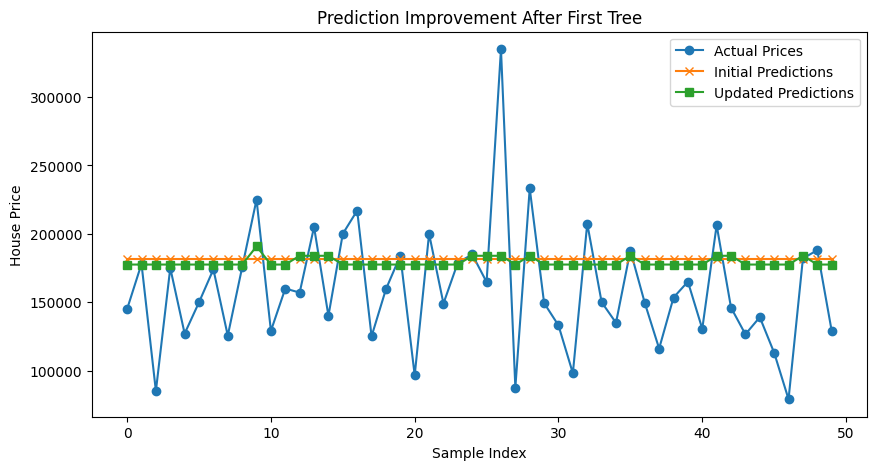

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(y_train.values[:50], label='Actual Prices', marker='o')
plt.plot(y_pred[:50], label='Initial Predictions', marker='x')
plt.plot(updated_predictions[:50], label='Updated Predictions', marker='s')

plt.title("Prediction Improvement After First Tree")
plt.xlabel("Sample Index")
plt.ylabel("House Price")
plt.legend()
plt.show()


In [29]:

# Initialize predictions with the mean
y_pred = np.full(len(y_train), initial_prediction)

# Store trained trees and MSE values
trees = []
mse_history = []

# Sequential boosting
for i in range(n_estimators):

    # Step 1: Calculate residuals
    residuals = y_train.values - y_pred

    # Step 2: Train a new decision tree
    tree = DecisionTreeRegressor(
        max_depth=max_depth,
        random_state=42 + i
    )

    tree.fit(X_train_processed, residuals)

    # Step 3: Predict residuals
    tree_predictions = tree.predict(X_train_processed)

    # Step 4: Update predictions
    y_pred += learning_rate * tree_predictions

    # Step 5: Store the tree
    trees.append(tree)

    # Step 6: Calculate MSE
    mse = mean_squared_error(y_train, y_pred)
    mse_history.append(mse)

    print(f"Iteration {i+1}")
    print(f"Training MSE: {mse:.2f}")
    print("-" * 40)


Iteration 1
Training MSE: 5259760471.04
----------------------------------------
Iteration 2
Training MSE: 4671034191.15
----------------------------------------
Iteration 3
Training MSE: 4182541088.73
----------------------------------------
Iteration 4
Training MSE: 3758930008.77
----------------------------------------
Iteration 5
Training MSE: 3403915635.81
----------------------------------------


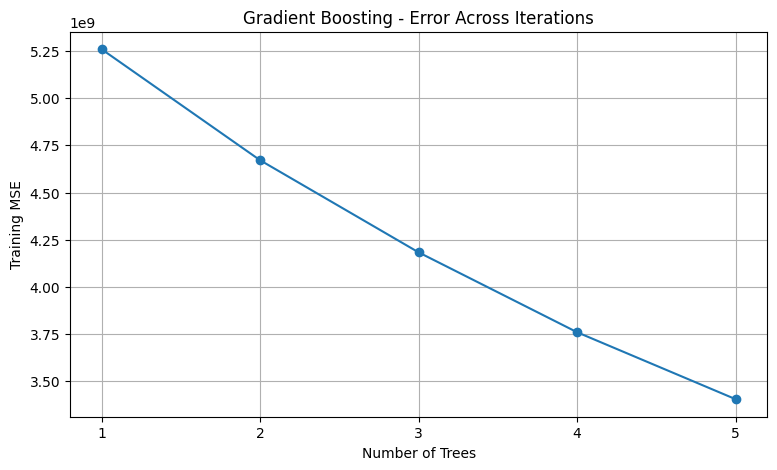

In [30]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, n_estimators + 1),
    mse_history,
    marker='o'
)

plt.xlabel("Number of Trees")
plt.ylabel("Training MSE")
plt.title("Gradient Boosting - Error Across Iterations")
plt.xticks(range(1, n_estimators + 1))
plt.grid(True)

plt.show()


In [31]:

mse_comparison = pd.DataFrame({
    'Iteration': range(1, n_estimators + 1),
    'Training MSE': mse_history
})

mse_comparison


,Iteration,Training MSE
0,1,5.259760e+09
1,2,4.671034e+09
2,3,4.182541e+09
3,4,3.758930e+09
4,5,3.403916e+09


In [32]:

# Final predictions after all boosting iterations

final_train_predictions = y_pred.copy()

print("Number of Trees Trained:", len(trees))

print("\nActual Prices:")
print(y_train.values[:10])

print("\nFinal Predictions:")
print(final_train_predictions[:10])


Number of Trees Trained: 5

Actual Prices:
[145000 178000  85000 175000 127000 149900 174000 125500 175500 225000]

Final Predictions:
[159838.42368253 178289.6730596  159838.42368253 169721.31394511
 169721.31394511 163335.34155266 178289.6730596  159838.42368253
 173792.72152709 215032.77457167]


## 8. Gradient Boosting Regression using Scikit-learn

Scikit-learn provides a built-in implementation of Gradient Boosting through `GradientBoostingRegressor`.

Instead of manually calculating residuals, training decision trees and updating predictions, the library handles the entire boosting process internally.

We only need to specify the hyperparameters and train the model.

### Important Hyperparameters

- `n_estimators`: Number of boosting stages (trees).
- `learning_rate`: Contribution of each tree.
- `max_depth`: Maximum depth of individual decision trees.
- `min_samples_split`: Minimum samples required to split a node.
- `min_samples_leaf`: Minimum samples required in a leaf node.
- `loss`: Loss function used for optimization.

In [33]:

from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    loss='squared_error',
    random_state=42
)


In [34]:

gbr.fit(X_train_processed, y_train)

print("Gradient Boosting Regressor trained successfully!")


Gradient Boosting Regressor trained successfully!


In [35]:

y_train_pred = gbr.predict(X_train_processed)
y_val_pred = gbr.predict(X_val_processed)

print("First 10 Actual Prices:")
print(y_val.values[:10])

print("\nFirst 10 Predicted Prices:")
print(y_val_pred[:10])


First 10 Actual Prices:
[154500 325000 115000 159000 315500  75500 311500 146000  84500 135500]

First 10 Predicted Prices:
[145103.18075161 340632.99655754 120814.71254643 150775.19405581
 339124.90846162  82869.69172067 220202.10207098 138662.13871738
  82869.69172067 135697.04788611]


In [36]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Training Performance")
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("MSE:", mean_squared_error(y_train, y_train_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("R2 Score:", r2_score(y_train, y_train_pred))

print("\nValidation Performance")
print("MAE:", mean_absolute_error(y_val, y_val_pred))
print("MSE:", mean_squared_error(y_val, y_val_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_val_pred)))
print("R2 Score:", r2_score(y_val, y_val_pred))


Training Performance
MAE: 9923.530898515697
MSE: 186459368.56933796
RMSE: 13655.012580343453
R2 Score: 0.9687387385976758

Validation Performance
MAE: 16535.108348521346
MSE: 693162744.5227176
RMSE: 26327.984057324207
R2 Score: 0.9096306042534121


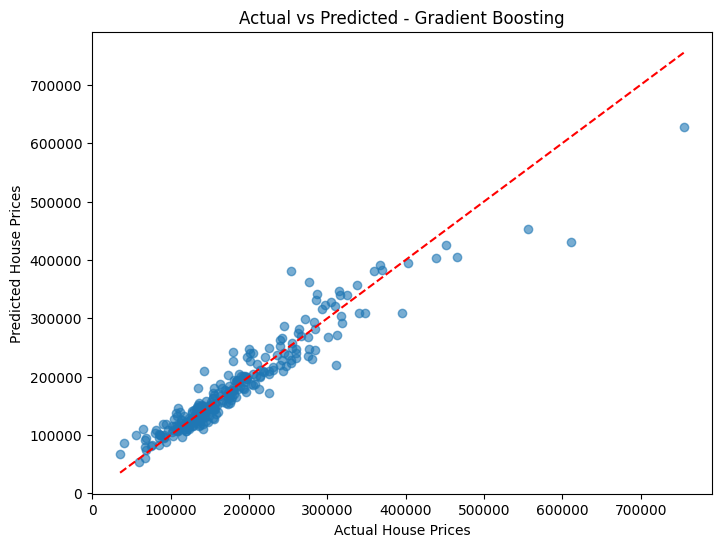

In [37]:

plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_val_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted - Gradient Boosting")

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    'r--'
)

plt.show()
